# Random forest - Team 61

Run from top to bottom after `python tune_svm.py`. Training code is in `randomforest.py`; the [report](../docs/report_1.md) has the longer discussion.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import HTML, Image, display
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import StratifiedKFold, train_test_split

BASE = Path.cwd()
if BASE.name == "notebooks":
    BASE = BASE.parent
sys.path.insert(0, str(BASE))

from preprocess import build_preprocessor
from randomforest import RandomForest, run_experiment, plot_results

train = pd.read_csv(BASE / "data/Customer_Train.csv")
test = pd.read_csv(BASE / "data/Customer_Test.csv")
X = train.drop(columns=["ID", "Segmentation"])
y = train["Segmentation"]
pd.options.display.float_format = "{:.3f}".format
print(f"{len(train):,} labelled customers · {len(test):,} test customers · {X.shape[1]} features")

1,838 labelled customers · 789 test customers · 9 features


## How many trees?

Compare depth 8 with unrestricted depth on the same five folds. OOB uses each tree’s excluded training rows; CV uses the held-out fold.

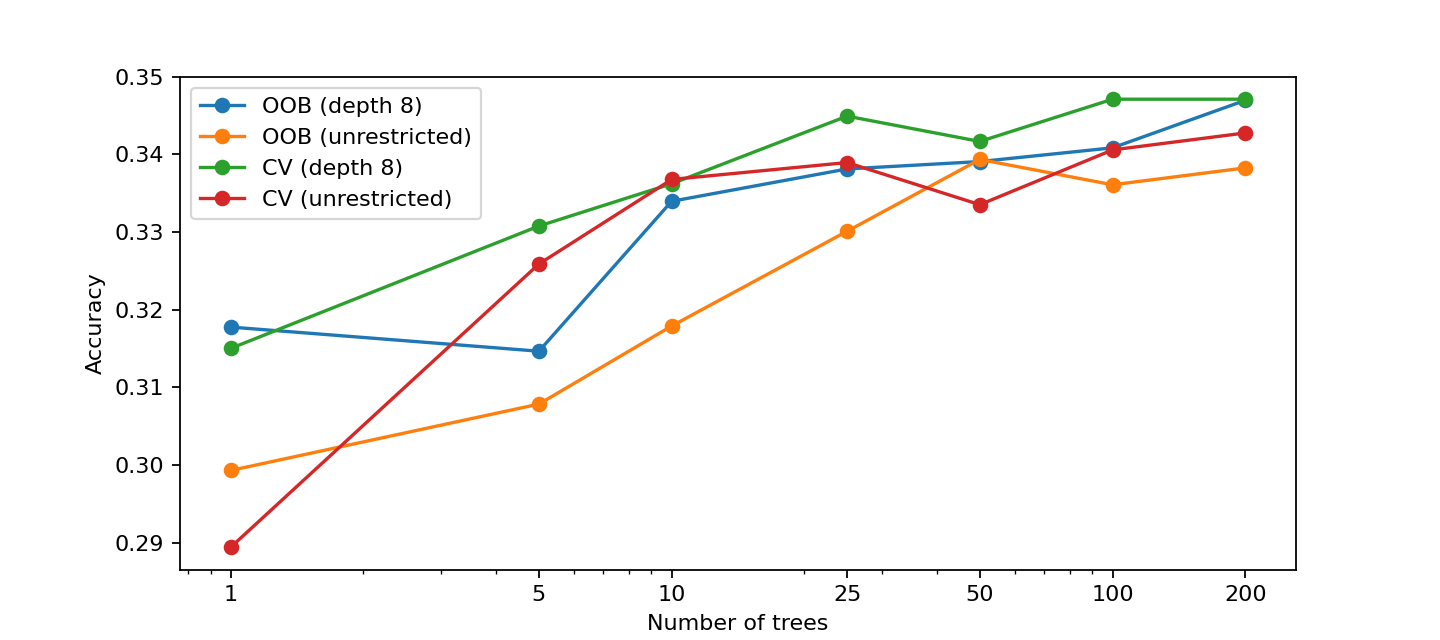

OOB accuracy  OOB SD  OOB coverage  CV accuracy  CV SD
Depth        Trees                                                        
8            1             0.318   0.018         0.369        0.315  0.022
             5             0.315   0.011         0.899        0.331  0.010
             10            0.334   0.009         0.991        0.336  0.004
             25            0.338   0.006         1.000        0.345  0.011
             50            0.339   0.009         1.000        0.342  0.011
             100           0.341   0.008         1.000        0.347  0.019
             200           0.347   0.007         1.000        0.347  0.019
unrestricted 1             0.299   0.011         0.369        0.289  0.030
             5             0.308   0.011         0.899        0.326  0.021
             10            0.318   0.007         0.991        0.337  0.018
             25            0.330   0.010         1.000        0.339  0.013
             50            0.339   0.008         1.000        0.334  0.019
             100           0.336   0.005         1.000        0.341  0.009
             200           0.338   0.004         1.000        0.343  0.011

In [2]:
summary = run_experiment()
plot_results(summary)
display(Image(filename=BASE / "results/figures/rf_tree_count_accuracy.png"))
display(summary.rename(columns={
    "max_depth": "Depth", "n_trees": "Trees", "cv_accuracy_mean": "CV accuracy",
    "cv_accuracy_std": "CV SD", "oob_accuracy_mean": "OOB accuracy",
    "oob_accuracy_std": "OOB SD", "oob_coverage_mean": "OOB coverage",
}).set_index(["Depth", "Trees"]))

Use the setting with the highest mean CV accuracy. More trees make voting steadier, but accuracy does not rise at every step.

## Check predictions on unseen rows

Each row is predicted using the other four folds. Fit preprocessing inside each fold.

In [3]:
best = summary.loc[summary["cv_accuracy_mean"].idxmax()]
N_TREES = int(best["n_trees"])
MAX_DEPTH = None if best["max_depth"] == "unrestricted" else int(best["max_depth"])
print(f"Selected {N_TREES} trees, depth {best['max_depth']}.")

oof = pd.read_csv(BASE / "results/oof_predictions.csv")
assert oof.ID.equals(train.ID) and oof.actual.equals(y)
oof["rf"] = ""
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for number, (train_rows, valid_rows) in enumerate(folds.split(X, y), start=1):
    assert oof.iloc[valid_rows]["fold"].eq(number).all()
    prep = build_preprocessor()
    X_train = prep.fit_transform(X.iloc[train_rows])
    X_valid = prep.transform(X.iloc[valid_rows])
    forest = RandomForest(N_TREES, MAX_DEPTH).fit(X_train, y.iloc[train_rows])
    oof.loc[valid_rows, "rf"] = forest.predict(X_valid)

report = classification_report(y, oof.rf, output_dict=True, zero_division=0)
display(pd.DataFrame({"Accuracy": [report["accuracy"]],
                      "Macro-F1": [report["macro avg"]["f1-score"]]}))
class_scores = pd.DataFrame(report).T.loc[["A", "B", "C", "D"]]
class_scores["support"] = class_scores["support"].astype(int)
display(class_scores.rename(columns={"precision": "Precision", "recall": "Recall",
                                    "f1-score": "F1", "support": "Customers"}))
oof.to_csv(BASE / "results/oof_predictions.csv", index=False)

Selected 200 trees, depth 8.


,Accuracy,Macro-F1
0,0.347,0.245


,Precision,Recall,F1,Customers
A,0.323,0.683,0.439,580
B,0.176,0.054,0.082,391
C,0.368,0.022,0.041,320
D,0.451,0.391,0.419,547


## Predict the new customers

Refit on all labelled rows. The full prediction table below scrolls; `rf.csv` contains the same 789 labels.

In [4]:
prep = build_preprocessor()
X_all = prep.fit_transform(X)
forest = RandomForest(N_TREES, MAX_DEPTH).fit(X_all, y)
predictions = pd.DataFrame({"predicted": forest.predict(prep.transform(test.drop(columns="ID")))})
predictions.to_csv(BASE / "rf.csv", index=False)
print(f"Saved {len(predictions)} predictions to rf.csv, in test-row order.")
display(predictions["predicted"].value_counts().sort_index().rename_axis("Segment").to_frame("Customers"))
display(HTML('<div style="max-height:260px; overflow:auto">'
             + predictions.to_html(index=False) + '</div>'))

Saved 789 predictions to rf.csv, in test-row order.


,Customers
Segment,
A,573
B,23
D,193


predicted
D
A
A
A
A
D
A
A
A
A


## Which attributes matter?

Fit on 80% of the labelled rows. On the remaining 20%, shuffle each original attribute ten times and measure the accuracy drop. A larger drop means the model relied more on that attribute.

In [5]:
X_fit, X_holdout, y_fit, y_holdout = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
prep = build_preprocessor()
forest = RandomForest(N_TREES, MAX_DEPTH).fit(prep.fit_transform(X_fit), y_fit)

def heldout_accuracy(model, raw_features, labels):
    return accuracy_score(labels, model.predict(prep.transform(raw_features)))

importance = permutation_importance(
    forest, X_holdout, y_holdout, scoring=heldout_accuracy,
    n_repeats=10, random_state=42
)
importance_table = pd.DataFrame({
    "attribute": X.columns,
    "accuracy_drop": importance.importances_mean,
    "std": importance.importances_std,
}).sort_values("accuracy_drop", ascending=False)
print(f"Held-out accuracy: {heldout_accuracy(forest, X_holdout, y_holdout):.3f}")
display(importance_table.set_index("attribute").rename(
    columns={"accuracy_drop": "Accuracy drop", "std": "SD across shuffles"}
))

Held-out accuracy: 0.342


,Accuracy drop,SD across shuffles
attribute,,
Age,0.017,0.007
Ever_Married,0.009,0.007
Family_Size,0.004,0.005
Var_1,0.001,0.007
Work_Experience,-0.001,0.008
Spending_Score,-0.003,0.004
Graduated,-0.004,0.006
Profession,-0.005,0.010
Gender,-0.006,0.006


**Age has the clearest effect:** about a 1.7 percentage-point accuracy drop. Age and marital status could reflect life stage and household needs. The smaller effects are less stable; these are associations, not causes.

## Compare with the SVMs

All three models use the same five folds. The table shows overall scores; the matrices show where each model makes mistakes.

,Accuracy,Macro-F1,Weighted-F1,Most confused
Model,,,,
OVA,0.341,0.310,0.329,A/D (376 errors)
OVO,0.351,0.215,0.264,A/D (482 errors)
RF,0.347,0.245,0.288,A/D (438 errors)


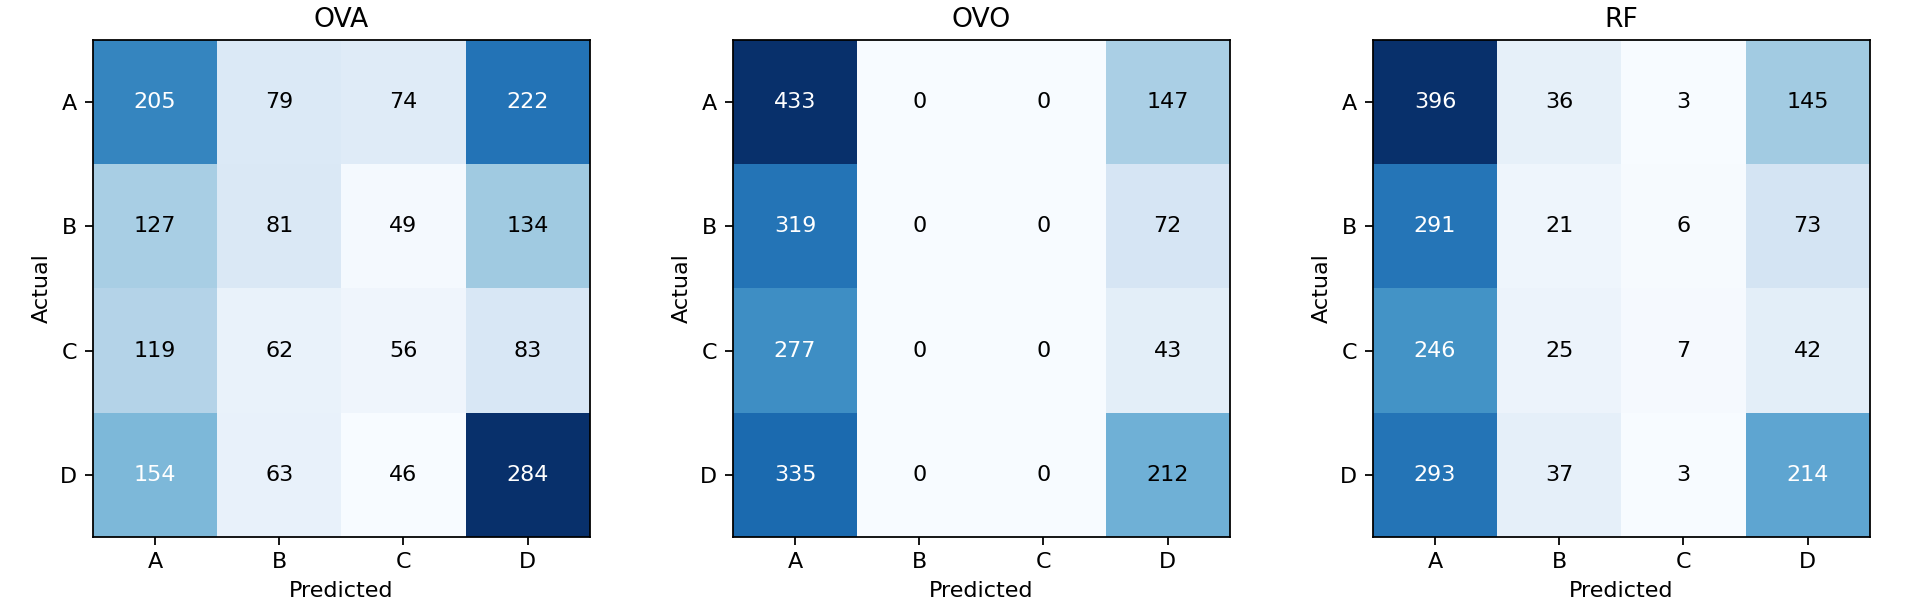

In [6]:
from task3_analysis import (
    model_reports, imbalance_experiment, validation_curves, compare_svms, baselines,
)
from tune_svm import prepare_folds

model_predictions = {"ova": oof.ova, "ovo": oof.ovo, "rf": oof.rf}
model_summary, per_class = model_reports(y, model_predictions)
display(model_summary.set_index("Model"))
display(Image(filename=BASE / "results/figures/task3_confusion_matrices.png"))

In [7]:
display(per_class[per_class["class"].isin(["A", "B", "C", "D"])].rename(columns={
    "model": "Model", "class": "Segment", "precision": "Precision",
    "recall": "Recall", "f1-score": "F1", "support": "Customers",
}).set_index(["Model", "Segment"]))

Precision  Recall    F1  Customers
Model Segment                                    
ova   A            0.339   0.353 0.346    580.000
      B            0.284   0.207 0.240    391.000
      C            0.249   0.175 0.206    320.000
      D            0.393   0.519 0.447    547.000
ovo   A            0.317   0.747 0.445    580.000
      B            0.000   0.000 0.000    391.000
      C            0.000   0.000 0.000    320.000
      D            0.447   0.388 0.415    547.000
rf    A            0.323   0.683 0.439    580.000
      B            0.176   0.054 0.082    391.000
      C            0.368   0.022 0.041    320.000
      D            0.451   0.391 0.419    547.000

### Does balancing the classes help?

Keep OVA’s RBF kernel, C=1 and gamma=0.1 fixed. Change only the class weights.

In [8]:
display(imbalance_experiment().rename(columns={
    "class_weight": "Weights", "accuracy_mean": "CV accuracy", "macro_f1_mean": "CV macro-F1",
}).set_index("Weights"))

,CV accuracy,CV macro-F1
Weights,,
unweighted,0.341,0.310
balanced,0.319,0.315


Balanced weights slightly improve macro-F1 here, with lower accuracy.

### Are the models overfitting?

Compare training and validation accuracy while changing one parameter at a time.

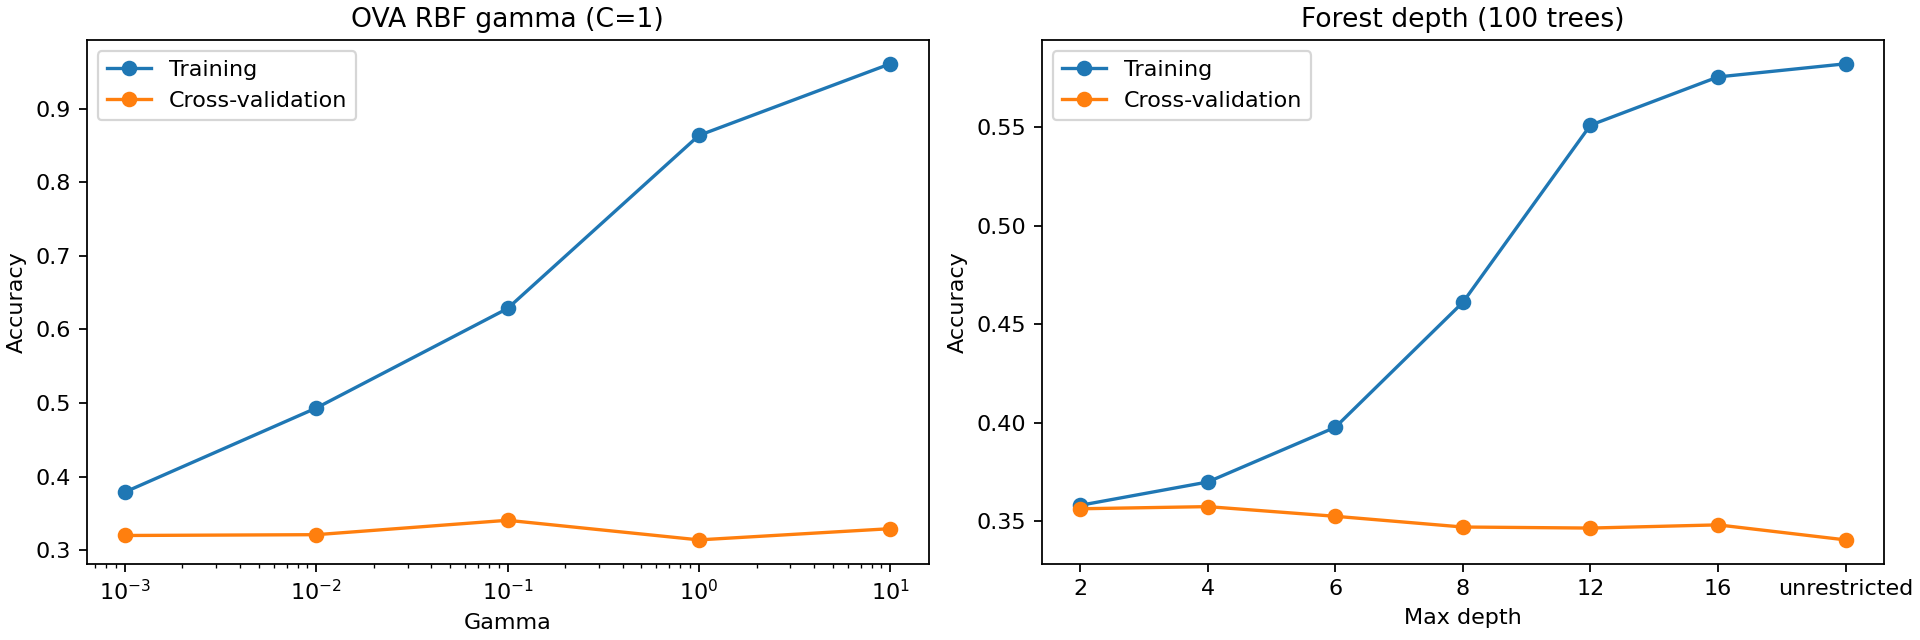

curve,value,train_accuracy,cv_accuracy
OVA RBF gamma (C=1),0.001,0.379,0.320
OVA RBF gamma (C=1),0.010,0.493,0.321
OVA RBF gamma (C=1),0.100,0.629,0.341
OVA RBF gamma (C=1),1.000,0.864,0.314
OVA RBF gamma (C=1),10.000,0.961,0.329
Forest depth (100 trees),2,0.358,0.356
Forest depth (100 trees),4,0.370,0.357
Forest depth (100 trees),6,0.398,0.353
Forest depth (100 trees),8,0.461,0.347
Forest depth (100 trees),12,0.551,0.347


In [9]:
prepared_folds, fold_ids = prepare_folds(X, y)
assert (oof["fold"].to_numpy() == fold_ids).all()
curves = validation_curves(prepared_folds)
display(Image(filename=BASE / "results/figures/task3_validation_curves.png"))
display(HTML('<details><summary>Show the curve values</summary>'
             + curves.round(3).to_html(index=False) + '</details>'))

Larger gamma and deeper trees improve training accuracy much more than validation accuracy. Depth 4 looks promising for further tuning; the main comparison uses the setting selected in the tree-count experiment.

### Is the improvement convincing?

Compare OVO and OVA on the same customer rows. The bootstrap resamples those pairs 10,000 times.

In [10]:
svm_comparison = compare_svms(y, oof.ova, oof.ovo)
display(svm_comparison.to_frame("Value").style.format("{:.4g}"))

,Value
OVO minus OVA accuracy,0.01034
95% CI lower,-0.0136
95% CI upper,0.03536
Only OVO correct,273
Only OVA correct,254
McNemar p-value,0.433


The interval crosses zero, and McNemar’s p-value is 0.433. OVO has no clear accuracy advantage; OVA has better macro-F1.

In [11]:
baseline_scores, best_model, p_value = baselines(X, y, model_predictions)
display(baseline_scores.set_index("Baseline"))
print(f"Best accuracy: {best_model.upper()}. One-sided binomial p-value vs majority: {p_value:.4g}")

Best accuracy: OVO. One-sided binomial p-value vs majority: 0.0006635


,Accuracy,Macro-F1
Baseline,,
majority,0.316,0.120
stratified random,0.254,0.241


Among the three selected models, OVO has the highest accuracy, about **3.5 percentage points** above the majority baseline. It still misses B and C entirely. OVA has better macro-F1. These folds also chose the settings, so the scores can be optimistic.